# MTLD curve: real tweets vs SG01 / SG02

MTLD (McCarthy & Jarvis 2010) reads the tweets end to end as one word stream and tracks the share of new words (TTR) since the last cut. When TTR falls to 0.72 the segment is cut and counting restarts. MTLD = average segment length, so fewer cuts = more varied wording.

Same samples as SQ01 / SQ02 (`src/sentiment/measure_quality.py`): 3,000 texts per set, `random.Random(42)`, whitespace tokens (`src/quality/lexical.py`). Real = S1 train, msa/egypt/gulf/levant only. The MTLD printed below must equal `results/quality/sentiment/sg0{1,2}_quality.json`.

In [1]:
import json
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt

# Run from the repo root whether the notebook is opened from notebooks/ or the root.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.quality.lexical import mtld, tokenize

VARIETIES = {"msa", "egypt", "gulf", "levant"}
GENERATORS = {"fanar": "Fanar", "qwen3": "Qwen3", "aya": "Aya"}
THRESHOLD, N_SAMPLE, SEED = 0.72, 3000, 42
N_WORDS = 8000   # words shown per panel

In [2]:
def read(path: str) -> list[dict]:
    """JSONL records with text."""
    with open(path, encoding="utf-8") as f:
        return [r for r in map(json.loads, f) if r.get("text")]


def sample_tokens(recs: list[dict]) -> list[str]:
    """The SQ01/SQ02 sample (3,000 texts, seed 42) as one whitespace-token stream."""
    chosen = random.Random(SEED).sample(recs, min(N_SAMPLE, len(recs)))
    return [t for r in chosen for t in tokenize(r["text"])]


def ttr_curve(tokens: list[str], threshold: float = THRESHOLD) -> tuple[list[float], list[int]]:
    """Running TTR since the last cut (forward pass, as MTLD counts it) and the word positions of the cuts."""
    curve, cuts, types, count = [], [], set(), 0
    for i, t in enumerate(tokens):
        types.add(t)
        count += 1
        value = len(types) / count
        curve.append(value)
        if value <= threshold:
            cuts.append(i + 1)
            types, count = set(), 0
    return curve, cuts


# All sets: real reference plus the selected (as-trained) synthetic sets.
sets = {"real": [r for r in read("data/processed/sentiment/arsarcasm_v2_train.jsonl") if r["dialect"] in VARIETIES]}
for run in ("sg01", "sg02"):
    for g in GENERATORS:
        sets[f"{run}_{g}"] = read(f"data/synthetic/sentiment/{run}_{g}.selected.jsonl")

curves = {}
for key, recs in sets.items():
    toks = sample_tokens(recs)
    curve, cuts = ttr_curve(toks)
    curves[key] = {"tokens": len(toks), "mtld": mtld(toks), "curve": curve, "cuts": cuts}

## Summary

In [3]:
print(f"{'set':12s} {'MTLD':>7s} {'cuts in first 8,000 words':>27s} {'tokens':>8s}")
for key, c in curves.items():
    n_cuts = sum(1 for x in c["cuts"] if x <= N_WORDS)
    print(f"{key:12s} {c['mtld']:7.1f} {n_cuts:27d} {c['tokens']:8,d}")

set             MTLD   cuts in first 8,000 words   tokens
real          2518.0                           3   45,709
sg01_fanar    1123.1                           6   41,020
sg01_qwen3     323.4                          24   41,831
sg01_aya       499.4                          15   51,915
sg02_fanar    1755.9                           4   45,192
sg02_qwen3     506.7                           8   45,857
sg02_aya      1053.1                           6   58,199


## Curves

One figure per generator: real tweets, zero-shot SG01 and few-shot SG02 on the same word axis. Dashed line = the 0.72 cut-off; grey ticks at the bottom = cuts.

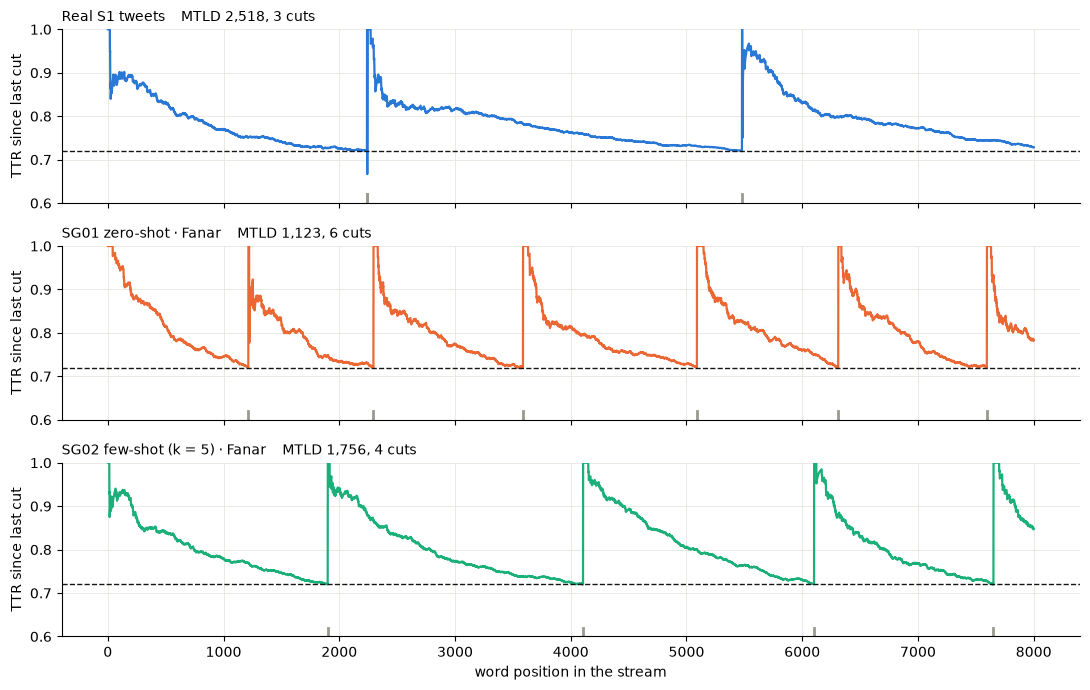

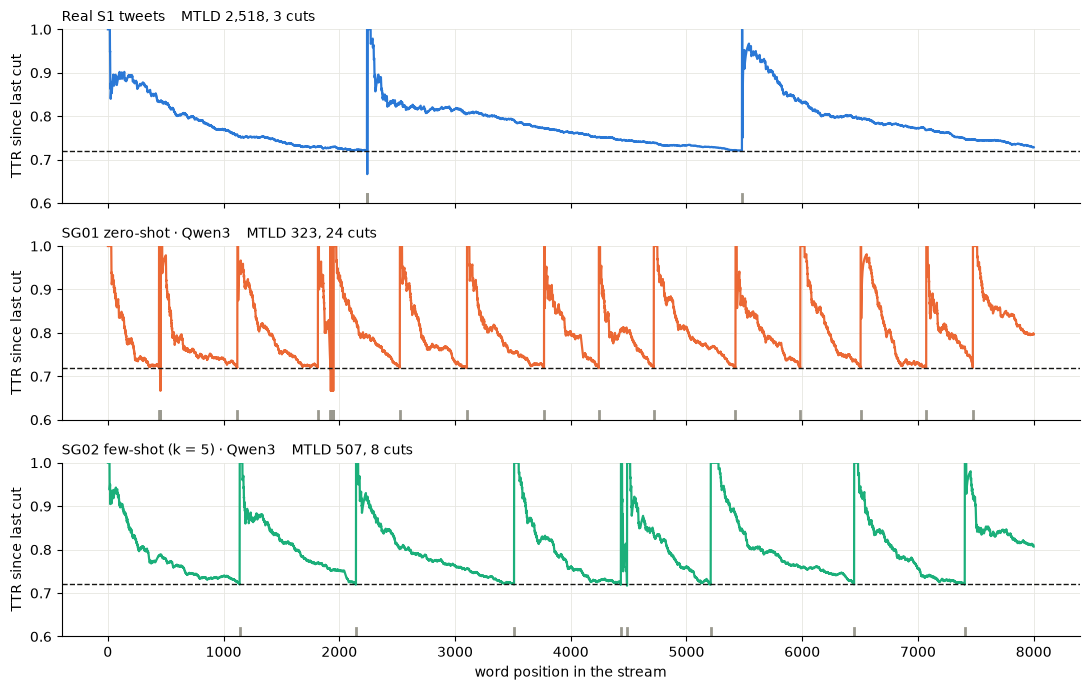

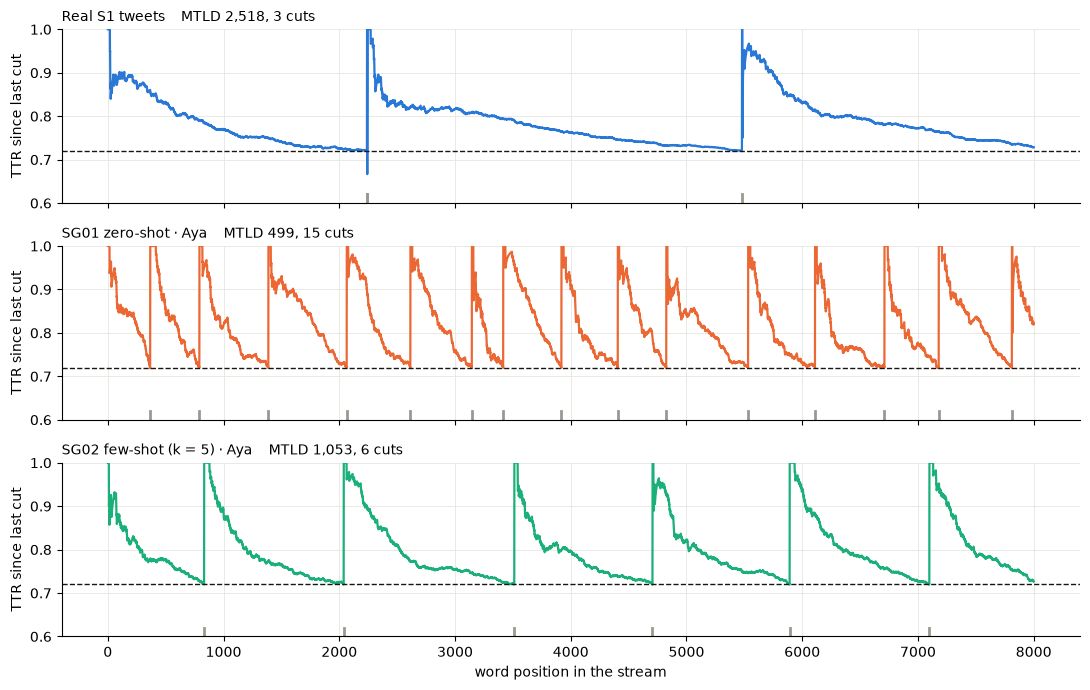

In [4]:
COLORS = {"real": "#2a78d6", "sg01": "#eb6834", "sg02": "#1baf7a"}   # dataviz reference palette, slots 1-3
NAMES = {"real": "Real S1 tweets", "sg01": "SG01 zero-shot", "sg02": "SG02 few-shot (k = 5)"}


def plot_generator(g: str) -> None:
    """Three stacked panels (real / SG01 / SG02) for one generator."""
    fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, sharey=True)
    for ax, (role, key) in zip(axes, [("real", "real"), ("sg01", f"sg01_{g}"), ("sg02", f"sg02_{g}")]):
        c = curves[key]
        ax.plot(range(1, N_WORDS + 1), c["curve"][:N_WORDS], color=COLORS[role], lw=1.6)
        ax.axhline(THRESHOLD, color="#151513", ls="--", lw=1)
        for x in c["cuts"]:
            if x <= N_WORDS:
                ax.plot([x, x], [0.6, 0.62], color="#9a998f", lw=2)
        n_cuts = sum(1 for x in c["cuts"] if x <= N_WORDS)
        title = NAMES[role] if role == "real" else f"{NAMES[role]} · {GENERATORS[g]}"
        ax.set_title(f"{title}    MTLD {c['mtld']:,.0f}, {n_cuts} cuts", loc="left", fontsize=10)
        ax.set_ylim(0.6, 1.0)
        ax.set_ylabel("TTR since last cut")
        ax.grid(True, color="#e7e6e1", lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
    axes[-1].set_xlabel("word position in the stream")
    fig.tight_layout()
    plt.show()


for g in GENERATORS:
    plot_generator(g)

## Check against the logged SQ01 / SQ02 values

Both should print `True`: the curves come from the same samples as the quality tables.

In [5]:
for run in ("sg01", "sg02"):
    logged = json.load(open(f"results/quality/sentiment/{run}_quality.json", encoding="utf-8"))["sets"]
    same = all(abs(curves[f"{run}_{g}"]["mtld"] - logged[g]["mtld"]) < 1e-6 for g in GENERATORS)
    same &= abs(curves["real"]["mtld"] - logged["real"]["mtld"]) < 1e-6
    print(run, same)

sg01 True
sg02 True
